# [EDA] 구조·품질 분석 — 2026-09-20

**작성자** — 김태은 (`taeeunni`)

**선행** — `260920_EDA_00_data_integrity_taeeunni.ipynb`에서 로딩 규칙을 확정했다.

**이 노트북이 답하는 것**

1. SK의 0은 실제 0인가 비식별 마스킹인가
2. 테이블 간 격자 커버리지 불일치는 분석에 얼마나 영향을 주는가
3. 카드의 비식별 컷(`USE_CNT>=5`)은 어느 집단을 지우는가 — **발표 핵심 논거**
4. 6개월 시계열에 수집 변동이나 이상치가 있는가

In [1]:
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import loaders, paths, regions
from src.features import card_cohort, isolation, sk_dong
from src.visualization.style import PALETTE, SGG_COLORS, setup_style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

FONT = setup_style()
print(f"한글 폰트: {FONT}")
print(f"pandas {pd.__version__} / numpy {np.__version__}")

한글 폰트: Malgun Gothic
pandas 3.0.6 / numpy 2.5.2


In [2]:
PK = loaders.SK_PK
age = loaders.load_sk("age", "202507")
time_ = loaders.load_sk("time", "202507")
wkdy = loaders.load_sk("wkdy", "202507")
print(f"2025-07 기준 격자 수 — AGE {len(age):,} / TIME {len(time_):,} / WKDY {len(wkdy):,}")

2025-07 기준 격자 수 — AGE 98,129 / TIME 94,099 / WKDY 117,825


## 1. 0값의 정체

플랜은 "0이 실제 0인지 비식별 하한 마스킹인지 문서에 없다"고 남겼다.
값의 이산 구조와 테이블 간 정합성으로 판별한다.

In [3]:
vals = time_[sk_dong.TIME_COLS].to_numpy().ravel()
pos = np.sort(np.unique(vals[vals > 0]))
gaps = np.diff(pos[:60])

print(f"양수 고유값 하위 20종")
print(pos[:20])
print()
print(f"인접 간격 최빈값: {pd.Series(gaps.round(4)).mode().tolist()}")
print(f"양수 최솟값: {pos.min()}   0.0254 미만 양수: {(pos < 0.0254).sum()}개")
print()
q = 0.0254
expected = np.round(np.arange(1, 21) * q, 2)
print("0.0254 배수를 2자리 반올림한 수열")
print(expected)
print(f"관측값과 일치: {np.array_equal(pos[:20], expected)}")

양수 고유값 하위 20종
[0.03 0.05 0.08 0.1  0.13 0.15 0.18 0.2  0.23 0.25 0.28 0.3  0.33 0.36
 0.38 0.41 0.43 0.46 0.48 0.51]

인접 간격 최빈값: [0.03]
양수 최솟값: 0.03   0.0254 미만 양수: 0개

0.0254 배수를 2자리 반올림한 수열
[0.03 0.05 0.08 0.1  0.13 0.15 0.18 0.2  0.23 0.25 0.28 0.3  0.33 0.36
 0.38 0.41 0.43 0.46 0.48 0.51]
관측값과 일치: True


In [4]:
# 증거 1 — 모든 칸이 0인 격자가 존재하는가
tc, ac, wc = sk_dong.TIME_COLS, sk_dong.AGE_COLS, sk_dong.WKDY_COLS
ev = {
    "TIME 24칸 전부 0인 격자": int((time_[tc].sum(axis=1) == 0).sum()),
    "AGE 12칸 전부 0인 격자": int((age[ac].sum(axis=1) == 0).sum()),
    "WKDY 7칸 전부 0인 격자": int((wkdy[wc].sum(axis=1) == 0).sum()),
}
a2 = age.assign(age_sum=age[ac].sum(axis=1)).set_index(PK)
w2 = wkdy.assign(wkdy_sum=wkdy[wc].sum(axis=1)).set_index(PK)
cm = a2.index.intersection(w2.index)
ev["AGE합=0 이면서 WKDY합>0"] = int(
    ((a2.loc[cm, "age_sum"] == 0) & (w2.loc[cm, "wkdy_sum"] > 0)).sum()
)
for k, v in ev.items():
    print(f"  {k}: {v:,}행")
print()
print("-> 전부 0이므로 '격자는 있는데 값이 통째로 지워진' 경우가 없다")

  TIME 24칸 전부 0인 격자: 0행
  AGE 12칸 전부 0인 격자: 0행
  WKDY 7칸 전부 0인 격자: 0행
  AGE합=0 이면서 WKDY합>0: 0행

-> 전부 0이므로 '격자는 있는데 값이 통째로 지워진' 경우가 없다


In [5]:
# 증거 2 — 0칸이 많은 격자에서 총량이 새는가 (마스킹이면 새야 한다)
tt = time_.drop_duplicates(subset=PK)
tt = tt.assign(time_sum=tt[tc].sum(axis=1), n_zero=(tt[tc] == 0).sum(axis=1))
m = a2.reset_index()[PK + ["age_sum"]].merge(tt[PK + ["time_sum", "n_zero"]], on=PK)
m["gap"] = m.age_sum - m.time_sum

bins = pd.cut(m.n_zero, [-1, 0, 3, 6, 12, 18, 24])
tab = m.groupby(bins, observed=True).agg(
    격자수=("gap", "size"), 평균격차=("gap", "mean"),
    평균AGE합=("age_sum", "mean"), 최대절대격차=("gap", lambda s: s.abs().max()),
).round(4)
print("시간대 0칸 개수별 AGE합 - TIME합")
print(tab.to_string())
print()
print("24칸 각각 소수 2자리 반올림 시 누적 오차 한계 = 24 x 0.005 = 0.12")
print("-> 관측 격차가 이 범위 안이면 마스킹이 아니라 반올림 오차다")

시간대 0칸 개수별 AGE합 - TIME합
            격자수   평균격차  평균AGE합  최대절대격차
n_zero                                
(-1, 0]   42945 -0.018 216.142   0.330
(0, 3]     7196 -0.041   3.446   0.310
(3, 6]    13039 -0.024   1.873   0.260
(6, 12]   20979 -0.059   0.582   0.390
(12, 18]   6290 -0.122   0.168   0.300
(18, 24]   2392  0.010   0.093   0.180

24칸 각각 소수 2자리 반올림 시 누적 오차 한계 = 24 x 0.005 = 0.12
-> 관측 격차가 이 범위 안이면 마스킹이 아니라 반올림 오차다


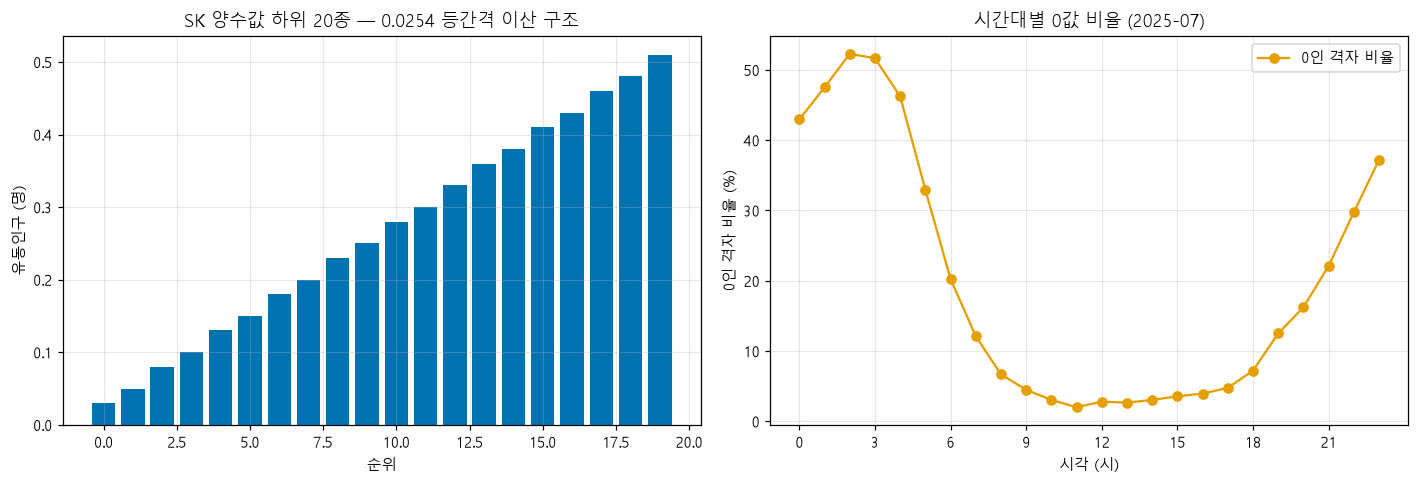

심야에 0이 많은 것은 실제로 사람이 없기 때문으로 해석된다


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.bar(range(len(pos[:20])), pos[:20], color=PALETTE[0])
ax.set_title("SK 양수값 하위 20종 — 0.0254 등간격 이산 구조")
ax.set_xlabel("순위")
ax.set_ylabel("유동인구 (명)")

ax = axes[1]
zero_share = [(time_[c] == 0).mean() * 100 for c in tc]
ax.plot(range(24), zero_share, marker="o", color=PALETTE[1], label="0인 격자 비율")
ax.set_title("시간대별 0값 비율 (2025-07)")
ax.set_xlabel("시각 (시)")
ax.set_ylabel("0인 격자 비율 (%)")
ax.set_xticks(range(0, 24, 3))
ax.legend()
plt.tight_layout()
plt.show()
print("심야에 0이 많은 것은 실제로 사람이 없기 때문으로 해석된다")

## 2. 격자 커버리지 불일치

3테이블의 격자 수가 다르다. 단순 조인하면 행이 사라진다.
그 행들이 무엇인지, 동 단위 집계 후에도 문제가 남는지 확인한다.

In [7]:
key = ["BLOCK_CD", "X_COORD", "Y_COORD"]
ka = set(map(tuple, age[key].values))
kt = set(map(tuple, time_.drop_duplicates(subset=PK)[key].values))
kw = set(map(tuple, wkdy[key].values))
common = ka & kt & kw

rows = []
for nm, ks, df, cols in (
    ("AGE", ka, age, ac), ("TIME", kt, time_.drop_duplicates(subset=PK), tc),
    ("WKDY", kw, wkdy, wc),
):
    d = df.copy()
    d["tot"] = d[cols].sum(axis=1)
    d["is_common"] = [tuple(x) in common for x in d[key].values]
    lost = d[~d.is_common]
    rows.append({
        "테이블": nm, "격자수": len(ks), "소실격자": len(lost),
        "소실격자비율%": round(len(lost) / len(ks) * 100, 2),
        "소실유동량비중%": round(lost.tot.sum() / d.tot.sum() * 100, 4),
        "소실격자_총유동_중앙값": round(lost.tot.median(), 3),
        "유지격자_총유동_중앙값": round(d[d.is_common].tot.median(), 3),
    })
cover = pd.DataFrame(rows)
print(f"3테이블 공통 격자: {len(common):,}")
print()
print(cover.to_string(index=False))
print()
print("-> 행 기준 최대 21% 소실이지만 유동인구 총량 기준으로는 0.02% 수준이다")

3테이블 공통 격자: 92,841

 테이블    격자수  소실격자  소실격자비율%  소실유동량비중%  소실격자_총유동_중앙값  유지격자_총유동_중앙값
 AGE  98129  5288    5.390     0.003         0.050         2.290
TIME  94099  1258    1.340     0.002         0.120         2.310
WKDY 117825 24984   21.200     0.021         0.480        16.130

-> 행 기준 최대 21% 소실이지만 유동인구 총량 기준으로는 0.02% 수준이다


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


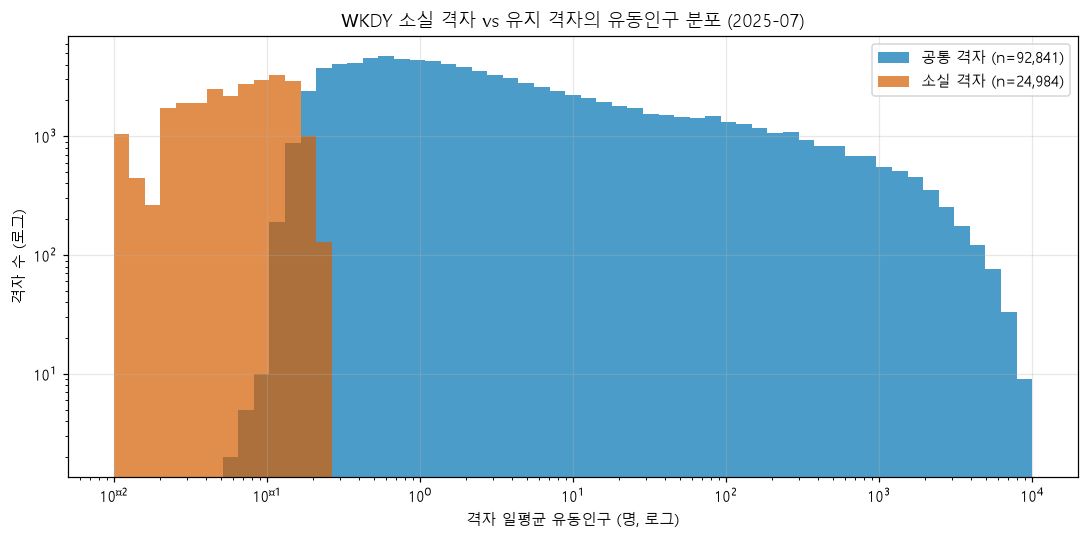

소실 격자 일평균 — 중앙값 0.069, 최댓값 0.261
유지 격자 일평균 — 중앙값 2.304, 최댓값 12,630.5


In [8]:
w3 = wkdy.copy()
w3["tot"] = w3[wc].sum(axis=1)
w3["is_common"] = [tuple(x) in common for x in w3[key].values]
w3["일평균"] = w3.tot / 7

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.logspace(-2, 4, 60)
ax.hist(w3.loc[w3.is_common, "일평균"].clip(lower=0.01), bins=bins,
        alpha=0.7, label=f"공통 격자 (n={int(w3.is_common.sum()):,})", color=PALETTE[0])
ax.hist(w3.loc[~w3.is_common, "일평균"].clip(lower=0.01), bins=bins,
        alpha=0.7, label=f"소실 격자 (n={int((~w3.is_common).sum()):,})", color=PALETTE[5])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("WKDY 소실 격자 vs 유지 격자의 유동인구 분포 (2025-07)")
ax.set_xlabel("격자 일평균 유동인구 (명, 로그)")
ax.set_ylabel("격자 수 (로그)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"소실 격자 일평균 — 중앙값 {w3.loc[~w3.is_common, '일평균'].median():.3f}, "
      f"최댓값 {w3.loc[~w3.is_common, '일평균'].max():.3f}")
print(f"유지 격자 일평균 — 중앙값 {w3.loc[w3.is_common, '일평균'].median():.3f}, "
      f"최댓값 {w3.loc[w3.is_common, '일평균'].max():,.1f}")

In [9]:
# 소실이 랜덤인가 — 지역·동별 분포
w3 = regions.add_region_codes(w3)
by_sgg = pd.crosstab(w3.sgg_cd, w3.is_common, normalize="index").mul(100).round(2)
by_sgg.columns = ["소실%", "유지%"]
print("시군구별 소실률")
print(by_sgg.to_string())
print()
dl = w3[w3.sgg_cd.isin(regions.TARGET_SGG)].groupby("dong_cd").agg(
    격자수=("tot", "size"),
    소실률=("is_common", lambda s: round((~s).mean() * 100, 2)),
    소실유동비중=("tot", "sum"),
)
lost_tot = w3[~w3.is_common].groupby("dong_cd").tot.sum()
dl["소실유동비중"] = (lost_tot.reindex(dl.index).fillna(0) / dl.소실유동비중 * 100).round(3)
print("행정동별 소실률 상위 8")
print(dl.sort_values("소실률", ascending=False).head(8).to_string())
print()
print("-> 소실은 랜덤이 아니라 춘천 저밀도 면 지역에 집중된다")

시군구별 소실률
          소실%     유지%
sgg_cd               
11030   0.000 100.000
11040   0.000 100.000
11220   0.000 100.000
11230   0.820  99.180
11240   0.000 100.000
31370   5.880  94.120
32010  24.240  75.760
32310  13.330  86.670
32370  75.000  25.000
32380  50.000  50.000



행정동별 소실률 상위 8
            격자수    소실률  소실유동비중
dong_cd                       
32010390   6898 43.140   3.631
32010380   9864 32.830   1.855
32010310  10405 31.480   0.348
32010360  14294 30.270   0.850
32010350   7227 30.040   0.874
32010340   7048 22.150   0.179
32010570   1871 21.590   0.050
32010330   4375 20.570   0.252

-> 소실은 랜덤이 아니라 춘천 저밀도 면 지역에 집중된다


In [10]:
# 동 단위 집계 후 테이블 간 총량 격차
panel = sk_dong.build_space_panel()
panel["age_sum"] = panel[ac].sum(axis=1)
panel["time_sum"] = panel[tc].sum(axis=1)
panel["rel"] = (panel.age_sum - panel.time_sum).abs() / panel.age_sum
panel["지역"] = panel.dong_cd.str[:5].map(regions.SGG_NAMES)

print("동x월 282행의 AGE합 vs TIME합 상대격차 (%)")
print((panel.rel * 100).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(4).to_string())
print()
print("지역별 (%)")
print((panel.groupby("지역").rel.agg(["mean", "max"]) * 100).round(4).to_string())
print()
print(f"전체 총량 기준 격차: "
      f"{(panel.age_sum.sum() - panel.time_sum.sum()) / panel.age_sum.sum() * 100:.5f}%")
print(f"상대격차 1% 초과: {int((panel.rel > 0.01).sum())} / {len(panel)} (동x월)")
print()
print("-> 중앙값 0.006%. 강남은 최대 0.03%로 사실상 없고,")
print("   춘천 면 지역 7개 동에서만 최대 3.3%다. 비율 지표를 쓰면 영향이 상쇄된다.")

동x월 282행의 AGE합 vs TIME합 상대격차 (%)
count   282.000
mean      0.278
std       0.632
min       0.000
50%       0.005
90%       1.062
95%       1.589
99%       2.859
max       3.325

지역별 (%)
        mean   max
지역                
강원 춘천시 0.519 3.325
서울 강남구 0.004 0.028

전체 총량 기준 격차: -0.03437%
상대격차 1% 초과: 32 / 282 (동x월)

-> 중앙값 0.006%. 강남은 최대 0.03%로 사실상 없고,
   춘천 면 지역 7개 동에서만 최대 3.3%다. 비율 지표를 쓰면 영향이 상쇄된다.


## 3. 비식별 컷 편향 정량화

카드 `USE_CNT` 최솟값이 5다. 5건 미만 집계셀이 삭제됐다는 뜻이다.
희소한 조합일수록 잘려 나가고, **우리가 찾는 고립 위험군이 바로 희소한 조합**이다.

정답을 볼 수 없으므로 두 지표로 간접 추정한다.

- `near_cut_share` — 살아남은 셀 중 `USE_CNT`가 최하단 밴드인 비율. 높을수록 절단선에 붙어 있다
- `combo_coverage` — 가능한 (업종 × 거주지) 조합 대비 실제 등장 비율. 낮을수록 많이 지워졌다

그 전에 `USE_CNT` 값 자체의 구조를 확인한다.

### 3.1 `USE_CNT`에 결측 정수 구간이 있다

데이터2의 `USE_CNT`는 단순한 원시 건수가 아니다. 특정 정수가 아예 등장하지 않는다.

In [11]:
card = card_cohort.prepare_card(2)
d1 = card_cohort.prepare_card(1)
print(f"데이터2 {len(card):,}행 / 데이터1 {len(d1):,}행")

rows = []
for v in range(1, 31):
    rows.append({
        "USE_CNT": v,
        "데이터2": int((card.USE_CNT == v).sum()),
        "데이터1": int((d1.USE_CNT == v).sum()),
    })
gap = pd.DataFrame(rows)
print()
print(gap.to_string(index=False))

데이터2 1,806,800행 / 데이터1 1,044,710행



 USE_CNT   데이터2   데이터1
       1      0      0
       2      0      0
       3      0      0
       4      0      0
       5 344145 117199
       6 176596  66888
       7      0   2842
       8      0   4316
       9      0   2803
      10      0     85
      11 121341  48783
      12  62217  30867
      13  46295  21072
      14      0   1237
      15      0   1874
      16  57890  26435
      17  37588  23396
      18  21819  11714
      19  18716   9520
      20      0     42
      21      0   1215
      22  32640  15692
      23  27690  17816
      24  18224  11197
      25   9508   6042
      26   4653   3555
      27  20465   9833
      28  17419  11773
      29  12828   8412
      30   7906   5576


In [12]:
miss2 = [v for v in range(1, 61) if (card.USE_CNT == v).sum() == 0]
miss1 = [v for v in range(1, 61) if (d1.USE_CNT == v).sum() == 0]
print(f"데이터2 결측 정수(1~60): {miss2}")
print(f"데이터1 결측 정수(1~60): {miss1}")
print()
print("데이터2 등장 구간: [5,6] [11,13] [16,19] [22 이상 연속]")
print("데이터1은 1~4만 없고 나머지는 존재하나 빈도가 비정상적으로 낮다")
print(f"  데이터1 USE_CNT=10 빈도: {int((d1.USE_CNT == 10).sum()):,}건")
print(f"  데이터1 USE_CNT=20 빈도: {int((d1.USE_CNT == 20).sum()):,}건")
print(f"  데이터1 USE_CNT=11 빈도: {int((d1.USE_CNT == 11).sum()):,}건 (비교용)")
print()
print("-> 데이터2는 5건 미만 절단에 더해 추가 비식별 처리를 받았다.")
print("   따라서 '절단선 근접'은 최하단 밴드인 USE_CNT <= 6으로 정의한다.")
print(f"   USE_CNT <= 6 인 셀 비율: {(card.USE_CNT <= card_cohort.NEAR_CUT_MAX).mean() * 100:.2f}%")

데이터2 결측 정수(1~60): [1, 2, 3, 4, 7, 8, 9, 10, 14, 15, 20, 21]
데이터1 결측 정수(1~60): [1, 2, 3, 4]

데이터2 등장 구간: [5,6] [11,13] [16,19] [22 이상 연속]
데이터1은 1~4만 없고 나머지는 존재하나 빈도가 비정상적으로 낮다
  데이터1 USE_CNT=10 빈도: 85건
  데이터1 USE_CNT=20 빈도: 42건
  데이터1 USE_CNT=11 빈도: 48,783건 (비교용)

-> 데이터2는 5건 미만 절단에 더해 추가 비식별 처리를 받았다.
   따라서 '절단선 근접'은 최하단 밴드인 USE_CNT <= 6으로 정의한다.
   USE_CNT <= 6 인 셀 비율: 28.82%


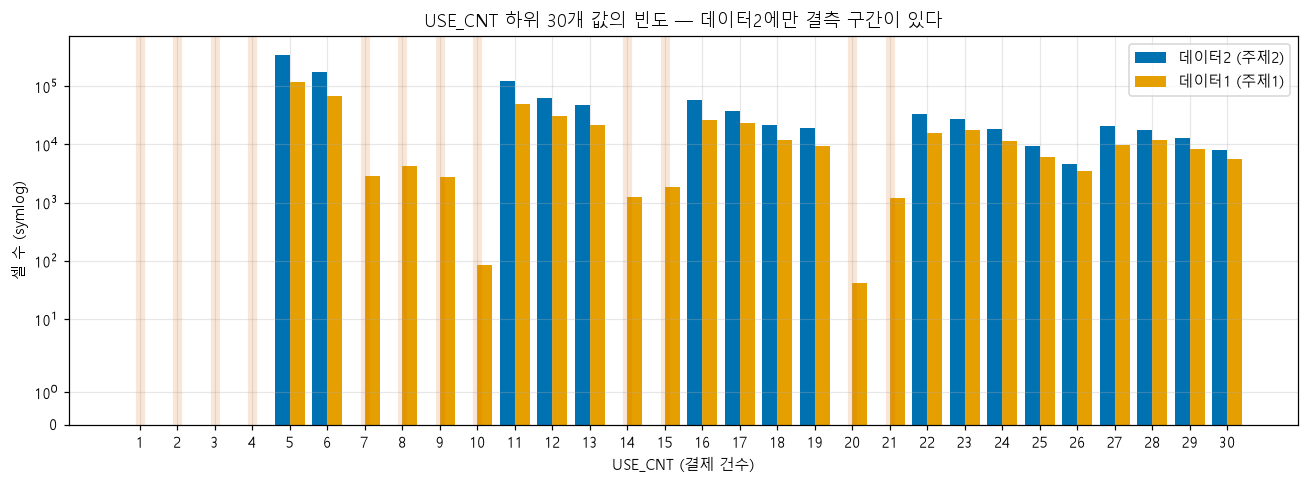

붉은 세로 띠가 데이터2에서 관측되지 않는 값이다


In [13]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(1, 31)
w = 0.4
ax.bar(x - w / 2, [int((card.USE_CNT == v).sum()) for v in x], w,
       label="데이터2 (주제2)", color=PALETTE[0])
ax.bar(x + w / 2, [int((d1.USE_CNT == v).sum()) for v in x], w,
       label="데이터1 (주제1)", color=PALETTE[1])
ax.set_yscale("symlog")
ax.set_title("USE_CNT 하위 30개 값의 빈도 — 데이터2에만 결측 구간이 있다")
ax.set_xlabel("USE_CNT (결제 건수)")
ax.set_ylabel("셀 수 (symlog)")
ax.set_xticks(x)
ax.legend()
for v in miss2:
    if v <= 30:
        ax.axvline(v, color=PALETTE[5], alpha=0.15, lw=6)
plt.tight_layout()
plt.show()
print("붉은 세로 띠가 데이터2에서 관측되지 않는 값이다")

### 3.2 어느 집단이 절단선에 붙어 있는가

In [14]:
by_age = card_cohort.truncation_stats(card, by=["age_band"])
by_age["near_cut_share%"] = (by_age.near_cut_share * 100).round(2)
by_age["combo_coverage%"] = (by_age.combo_coverage * 100).round(2)
print("연령대별 절단 근접도와 조합 커버리지")
print(by_age[["age_band", "n_cells", "near_cut_share%", "median_use_cnt",
              "observed_combos", "combo_coverage%"]].to_string(index=False))

연령대별 절단 근접도와 조합 커버리지
 age_band  n_cells  near_cut_share%  median_use_cnt  observed_combos  combo_coverage%
       10    97507           36.230          13.000             1030           67.320
       20   280601           27.840          23.000             1384           90.460
       30   319358           26.190          24.000             1430           93.460
       40   312364           26.160          27.000             1444           94.380
       50   311101           27.660          22.000             1448           94.640
       60   239888           29.900          22.000             1393           91.050
       70   154013           30.810          17.000             1251           81.760
       80    75176           37.090          12.000              912           59.610
       90    16792           52.550           6.000              429           28.040


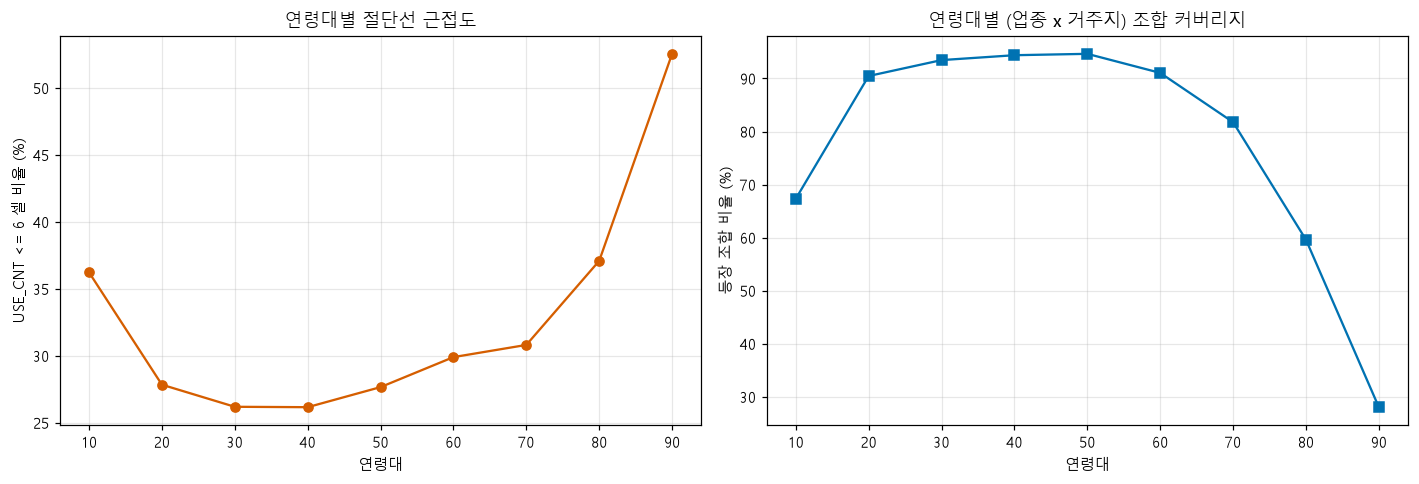

10대 절단근접 36.2% / 커버리지 67.3%
90대 절단근접 52.5% / 커버리지 28.0%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(by_age.age_band, by_age["near_cut_share%"], marker="o", color=PALETTE[5])
ax.set_title("연령대별 절단선 근접도")
ax.set_xlabel("연령대")
ax.set_ylabel("USE_CNT <= 6 셀 비율 (%)")

ax = axes[1]
ax.plot(by_age.age_band, by_age["combo_coverage%"], marker="s", color=PALETTE[0])
ax.set_title("연령대별 (업종 x 거주지) 조합 커버리지")
ax.set_xlabel("연령대")
ax.set_ylabel("등장 조합 비율 (%)")
plt.tight_layout()
plt.show()

lo, hi = by_age.iloc[0], by_age.iloc[-1]
print(f"10대 절단근접 {lo['near_cut_share%']:.1f}% / 커버리지 {lo['combo_coverage%']:.1f}%")
print(f"90대 절단근접 {hi['near_cut_share%']:.1f}% / 커버리지 {hi['combo_coverage%']:.1f}%")

In [16]:
by_sgg_t = card_cohort.truncation_stats(card, by=["MCT_SGG_CD"])
by_sgg_t["near_cut_share%"] = (by_sgg_t.near_cut_share * 100).round(2)
by_sgg_t["combo_coverage%"] = (by_sgg_t.combo_coverage * 100).round(2)
print("지역별")
print(by_sgg_t[["MCT_SGG_CD", "n_cells", "near_cut_share%", "median_use_cnt",
                "combo_coverage%"]].to_string(index=False))
print()

by_ry = card_cohort.truncation_stats(card, by=["MCT_RY_CD"])
by_ry["near_cut_share%"] = (by_ry.near_cut_share * 100).round(2)
top = by_ry.nlargest(10, "near_cut_share")[["MCT_RY_CD", "n_cells", "near_cut_share%",
                                            "median_use_cnt"]]
bot = by_ry.nsmallest(5, "near_cut_share")[["MCT_RY_CD", "n_cells", "near_cut_share%",
                                            "median_use_cnt"]]
print("절단선에 가장 가까운 업종 10종")
print(top.to_string(index=False))
print()
print("가장 먼 업종 5종")
print(bot.to_string(index=False))

지역별
MCT_SGG_CD  n_cells  near_cut_share%  median_use_cnt  combo_coverage%
    강원 춘천시   440611           37.440          13.000           81.700
    서울 강남구  1366189           26.040          25.000           95.230



절단선에 가장 가까운 업종 10종
  MCT_RY_CD  n_cells  near_cut_share%  median_use_cnt
      중고차판매       41           92.680           5.000
      부동산중개     1322           75.870           5.000
장례식장/묘지/장의사     2302           74.980           5.000
      수입자동차     2291           68.490           5.000
      수제용품점     3274           65.820           6.000
       오토바이     2086           63.900           6.000
   법률/사무서비스     2214           63.460           5.000
      학교등록금       93           63.440           5.000
         가구     4522           59.770           6.000
     안마/마사지     3464           57.740           6.000

가장 먼 업종 5종
   MCT_RY_CD  n_cells  near_cut_share%  median_use_cnt
   컴퓨터/소프트웨어    45788            7.660         395.000
         쇼핑몰    41977            7.760         192.000
       세금공과금    38317            9.480         115.000
      ZZ_나머지    63438            9.820         350.000
할인점/슈퍼마켓/양판점    72161           12.730         240.000


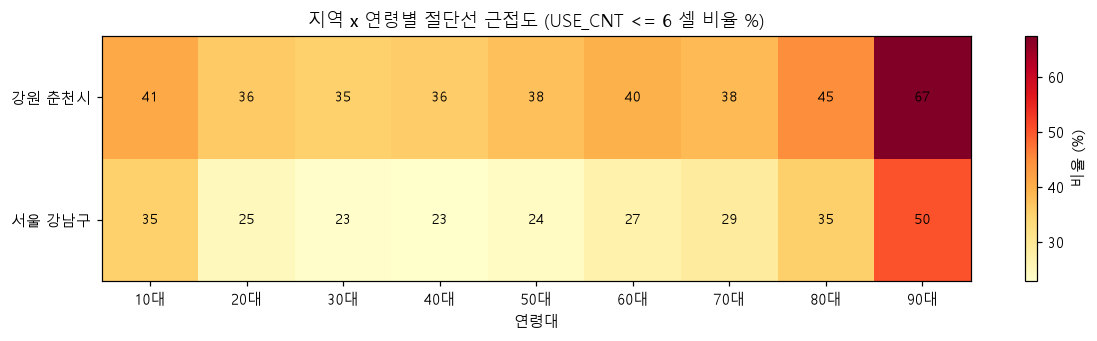

사회적 업종 12종만 따로 보면


 age_band  n_cells  near_cut_share%  median_use_cnt
       10    26019           34.550          18.000
       20    61885           24.690          29.000
       30    60169           23.630          32.000
       40    55861           24.030          32.000
       50    58691           25.800          27.000
       60    43816           26.560          23.000
       70    27257           30.720          17.000
       80    12651           39.470          12.000
       90     3309           43.970          11.000


In [17]:
# 연령 x 지역 교차
cross = card_cohort.truncation_stats(card, by=["MCT_SGG_CD", "age_band"])
piv = cross.pivot(index="MCT_SGG_CD", columns="age_band", values="near_cut_share").mul(100)

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(piv.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels([f"{c}대" for c in piv.columns])
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels(piv.index)
ax.set_title("지역 x 연령별 절단선 근접도 (USE_CNT <= 6 셀 비율 %)")
ax.set_xlabel("연령대")
ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="비율 (%)")
plt.tight_layout()
plt.show()

print("사회적 업종 12종만 따로 보면")
soc = card[card.is_social]
soc_stats = card_cohort.truncation_stats(soc, by=["age_band"])
soc_stats["near_cut_share%"] = (soc_stats.near_cut_share * 100).round(2)
print(soc_stats[["age_band", "n_cells", "near_cut_share%", "median_use_cnt"]].to_string(index=False))

## 4. 시계열 무결성

월별 고유 격자 수 (중복 제거 후)
table      age   time    wkdy
ym                           
202507   98129  94099  117825
202508   99115  95374  118958
202509   99469  95084  119865
202510  100750  97881  120643
202511  100444  95822  122248
202512   98345  92545  121267

월별 변화율 (%)
table     age   time   wkdy
ym                         
202507    NaN    NaN    NaN
202508  1.000  1.350  0.960
202509  0.360 -0.300  0.760
202510  1.290  2.940  0.650
202511 -0.300 -2.100  1.330
202512 -2.090 -3.420 -0.800


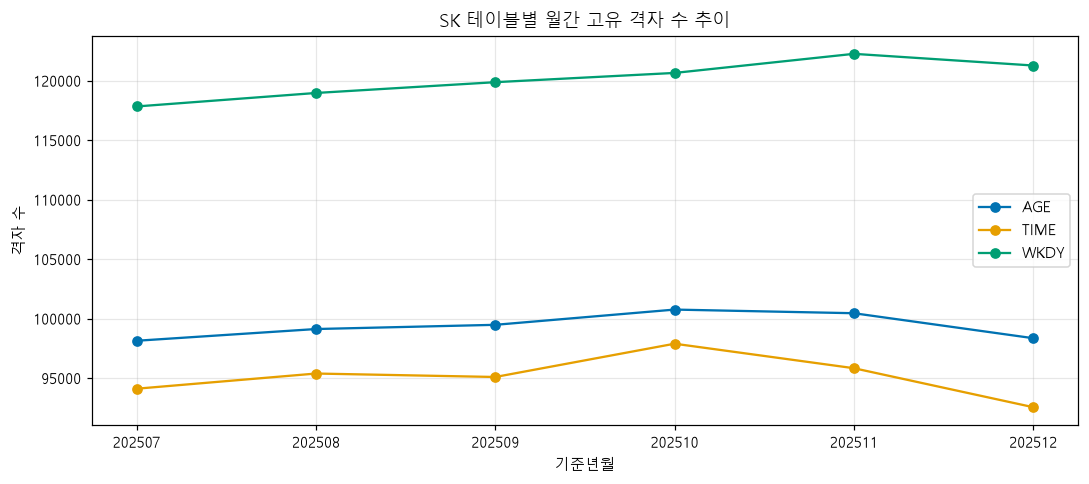

In [18]:
rep = loaders.dedupe_report()
piv_m = rep.pivot(index="ym", columns="table", values="rows_dedup")
print("월별 고유 격자 수 (중복 제거 후)")
print(piv_m.to_string())
print()
print("월별 변화율 (%)")
print((piv_m.pct_change() * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, t in enumerate(piv_m.columns):
    ax.plot(piv_m.index, piv_m[t], marker="o", label=t.upper(), color=PALETTE[i])
ax.set_title("SK 테이블별 월간 고유 격자 수 추이")
ax.set_xlabel("기준년월")
ax.set_ylabel("격자 수")
ax.legend()
plt.tight_layout()
plt.show()

기간 내 누락일: 0일
일별 행수 — 평균 9,820 / 최소 7,667 / 최대 10,760


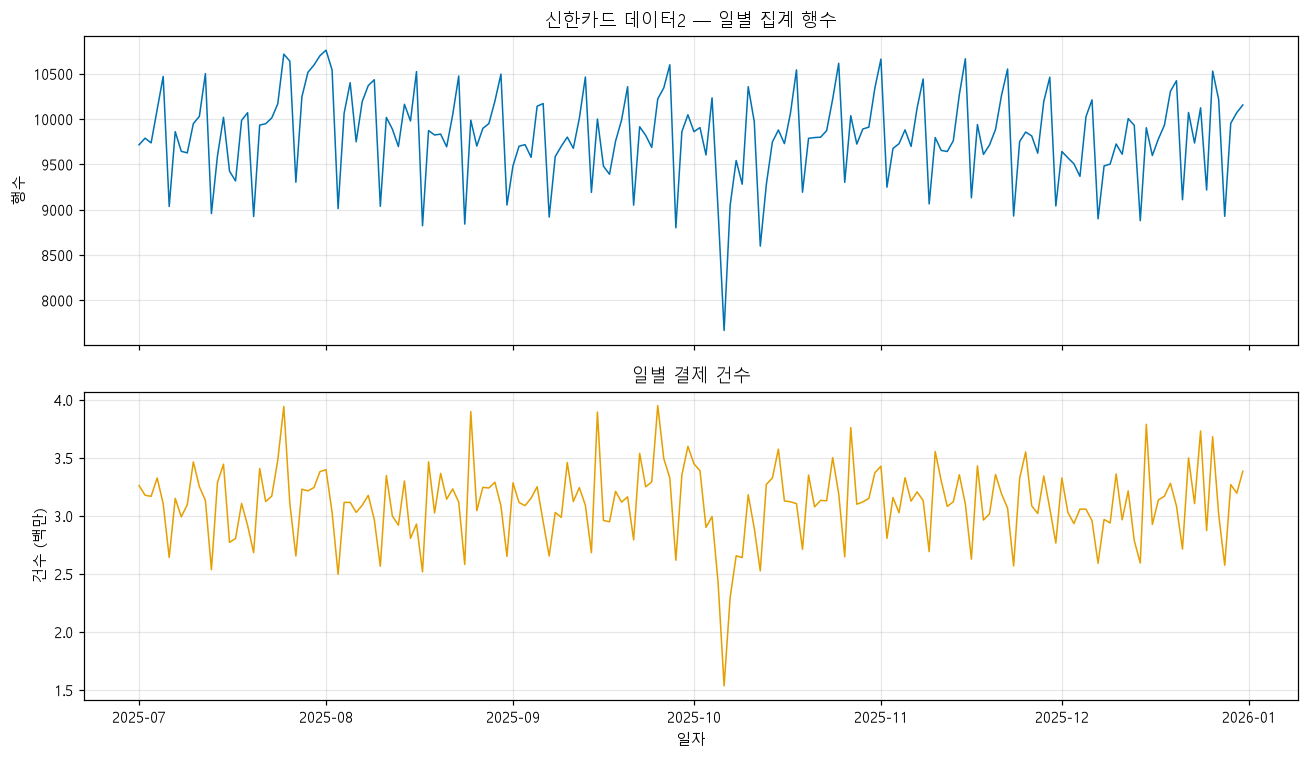

In [19]:
daily = card.groupby("TA_YMD").agg(행수=("USE_CNT", "size"), 건수=("USE_CNT", "sum"),
                                    금액=("TS_AT", "sum")).reset_index()
daily["date"] = pd.to_datetime(daily.TA_YMD, format="%Y%m%d")
daily["요일"] = daily.date.dt.dayofweek.map(
    {0: "월", 1: "화", 2: "수", 3: "목", 4: "금", 5: "토", 6: "일"})

missing = pd.date_range("2025-07-01", "2025-12-31").difference(daily.date)
print(f"기간 내 누락일: {len(missing)}일")
print(f"일별 행수 — 평균 {daily.행수.mean():,.0f} / 최소 {daily.행수.min():,} / 최대 {daily.행수.max():,}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(daily.date, daily.행수, color=PALETTE[0], lw=1)
axes[0].set_title("신한카드 데이터2 — 일별 집계 행수")
axes[0].set_ylabel("행수")
axes[1].plot(daily.date, daily.건수 / 1e6, color=PALETTE[1], lw=1)
axes[1].set_title("일별 결제 건수")
axes[1].set_ylabel("건수 (백만)")
axes[1].set_xlabel("일자")
plt.tight_layout()
plt.show()

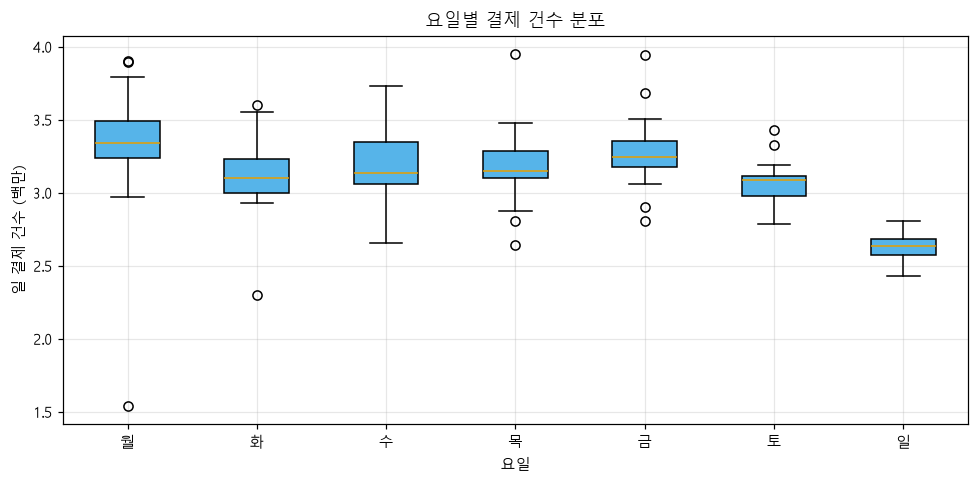

결제 건수 하위 10일 (공휴일 후보)
  TA_YMD 요일   행수      건수
20251006  월 7667 1536182
20251007  화 9046 2296515
20251005  일 8996 2428310
20250803  일 9012 2497041
20250817  일 8823 2518327
20251012  일 8598 2525878
20250713  일 8957 2536828
20250810  일 9037 2566439
20251123  일 8930 2569149
20251228  일 8927 2574659

결제 건수 상위 5일
  TA_YMD 요일    행수      건수
20250925  목 10223 3950740
20250725  금 10716 3943221
20250825  월  9988 3899220
20250915  월 10000 3893955
20251215  월  9904 3789112


In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = ["월", "화", "수", "목", "금", "토", "일"]
data = [daily.loc[daily.요일 == d, "건수"].values / 1e6 for d in order]
bp = ax.boxplot(data, tick_labels=order, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor(PALETTE[4])
ax.set_title("요일별 결제 건수 분포")
ax.set_xlabel("요일")
ax.set_ylabel("일 결제 건수 (백만)")
plt.tight_layout()
plt.show()

print("결제 건수 하위 10일 (공휴일 후보)")
print(daily.nsmallest(10, "건수")[["TA_YMD", "요일", "행수", "건수"]].to_string(index=False))
print()
print("결제 건수 상위 5일")
print(daily.nlargest(5, "건수")[["TA_YMD", "요일", "행수", "건수"]].to_string(index=False))

## 5. 분포 구조

In [21]:
dong_tot = panel.groupby(["dong_cd", "지역"], observed=True).age_sum.mean().reset_index()
print("행정동별 월평균 총유동 분포")
print(dong_tot.groupby("지역").age_sum.describe(
    percentiles=[0.25, 0.5, 0.75]).round(0).to_string())
print()
print(f"강남/춘천 동 평균 배율: "
      f"{dong_tot[dong_tot.지역 == '서울 강남구'].age_sum.mean() / dong_tot[dong_tot.지역 == '강원 춘천시'].age_sum.mean():.2f}배")

g = age.copy()
g["tot"] = g[ac].sum(axis=1)
g = g.sort_values("tot", ascending=False)
top1 = int(len(g) * 0.01)
print(f"\n격자 상위 1%({top1:,}개)가 차지하는 유동인구 비중: "
      f"{g.head(top1).tot.sum() / g.tot.sum() * 100:.2f}%")
print(f"격자 상위 10%가 차지하는 비중: {g.head(len(g) // 10).tot.sum() / g.tot.sum() * 100:.2f}%")

행정동별 월평균 총유동 분포
        count        mean         std        min         25%         50%         75%           max
지역                                                                                                
강원 춘천시 25.000  74,246.000  68,871.000  4,597.000  27,612.000  57,849.000  80,968.000   292,482.000
서울 강남구 22.000 335,143.000 245,231.000 81,612.000 194,544.000 283,754.000 421,798.000 1,240,733.000

강남/춘천 동 평균 배율: 4.51배

격자 상위 1%(981개)가 차지하는 유동인구 비중: 35.53%
격자 상위 10%가 차지하는 비중: 89.61%


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


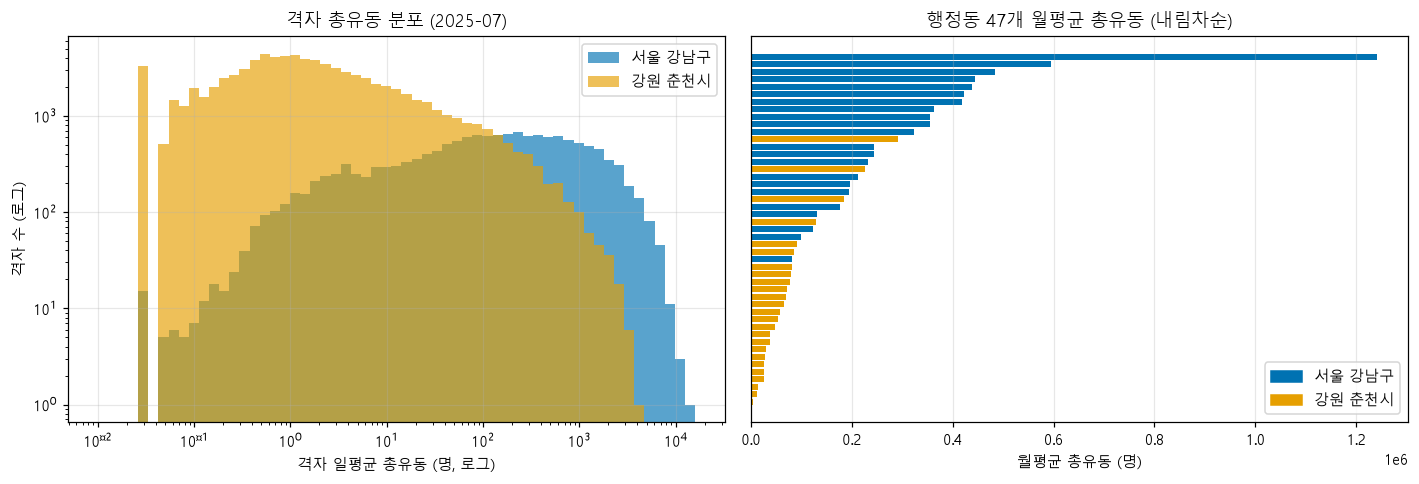

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
bins = np.logspace(-2, 4.2, 60)
for i, (cd, nm) in enumerate(regions.SGG_NAMES.items()):
    sub = g[g.BLOCK_CD.str[:5] == cd]
    ax.hist(sub.tot.clip(lower=0.01), bins=bins, alpha=0.65, label=nm, color=PALETTE[i])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("격자 총유동 분포 (2025-07)")
ax.set_xlabel("격자 일평균 총유동 (명, 로그)")
ax.set_ylabel("격자 수 (로그)")
ax.legend()

ax = axes[1]
dd = dong_tot.sort_values("age_sum", ascending=False)
colors = [SGG_COLORS[z] for z in dd.지역]
ax.barh(range(len(dd)), dd.age_sum, color=colors)
ax.set_yticks([])
ax.invert_yaxis()
ax.set_title("행정동 47개 월평균 총유동 (내림차순)")
ax.set_xlabel("월평균 총유동 (명)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SGG_COLORS.values()]
ax.legend(handles, list(SGG_COLORS), loc="lower right")
plt.tight_layout()
plt.show()

## 핵심 발견

**1. SK의 0은 비식별 마스킹이 아니라 실제 0일 가능성이 높다.**
모든 값이 0.0254의 정수배이고 그 미만 양수가 하나도 없다.
24칸·12칸·7칸이 전부 0인 격자가 0행이고, `AGE`합=0이면서 `WKDY`합>0인 격자도 0행이다.
0칸이 많은 격자에서 관측된 총량 격차(최대 0.12)는 24칸 반올림 누적 오차 한계와 정확히 일치한다.
따라서 0을 결측으로 처리하지 않는다.

**2. 격자 커버리지 불일치는 행 기준 21%지만 정보량 기준 0.02%다.**
소실 격자의 일평균 유동인구는 중앙값 0.069명, 최댓값 0.261명으로 사실상 빈 격자다.
다만 소실은 랜덤이 아니라 춘천 저밀도 면 지역에 집중된다.
동 단위 집계 시 테이블 간 총량 격차는 중앙값 0.006%, 강남 최대 0.03%로 무시 가능하나
춘천 면 7개 동에서는 최대 3.3%가 남는다. 절대량 대신 비율 지표를 쓴다.

**3. 비식별 컷은 고령층·춘천·희소 업종을 체계적으로 지우며, 데이터2는 추가 가공까지 받았다.**

데이터2의 `USE_CNT`에는 `1~4`뿐 아니라 `7~10`, `14~15`, `20~21`이 아예 없다.
등장 구간이 `[5,6] [11,13] [16,19] [22~]`로 22 이상부터만 연속이다.
같은 출처인 데이터1에는 `1~4`만 없고 나머지는 모두 존재한다.
즉 데이터2는 5건 미만 절단에 더해 **추가 비식별 처리**를 받았다.
`USE_CNT`를 원시 건수로 다루면 안 되고, 건당 결제액은 최하단 구간에서 왜곡된다.

절단 편향의 방향은 명확하다. 연령대별 절단선 근접도와 조합 커버리지가 U자를 그리며
90대에서 가장 나쁘고, 춘천이 강남보다 일관되게 나쁘다.
이는 고립 위험군을 찾는 분석에 정확히 역방향으로 작용한다. 발표 자료의 핵심 논거로 쓴다.

**다음 단계** — 2단계에서 강남·춘천의 인구·시간 패턴을 대조하고 타겟 지역을 좁힌다.